# **Healthcare Insurance Cost Analysis Project:**

This project set out to explore how Data Analytics and AI tools can be use to extract inside information from raw datasets into meaningful insights that utilise for prediction and decesion manking in data driven organisation and for business success. The healthcare Insurance Cost Analysis Project seeks empirically to explore systematic approach to analyse raw datasets and its rationale to identify how different Age, Gender, Body mass index, Somking habit and Various Geography affect health insurence cost. In this Jupyter notebook, therefore, analysing and visualise the data in three core sections -
- Section 1: Data cleaning ETL (Extract, Transform and Load) and EDA (Exploratory Data Analysis)
- Section 2: Probability and Statistical analysis for the Dataset
- Section 3: Machine Learning algorithm and techniques

For this analysis fetch data from Kaggle and save to local drive. Data then clean and processed for visualisation using Python programming language and its libraries. In this analysis Pyhton 3.12.8 version used and the Libraries used - Numpy, Pandas, Matplotlib, Seaborn, plotly, SciKit-learn

**Setting up working environment and directory**

Access the current directory with os.getcwd()

In [65]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Users\\skmra\\Documents\\Project2'

Make the parent of the current directory the new current directory with os.path.dirname() to get the parent directory and os.chir() defines the new current directory

In [66]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [67]:
current_dir = os.getcwd()
current_dir

'c:\\Users\\skmra\\Documents'

# Section 1

**Import, Clean, Transform and save as a clean dataset for visualisation and further analysis**

**1.0 Import Python libraries and Dataset**

Import pandas library which run on top of numerical python: Numpy backed by core python terminal. To import data file from souce can be performed in various ways by defining the file path on pandas data frame. Since, this project data already downloaded from Kaggle.com and store in local computer, local file path will use. However, direct source link can be used if required by providing full file path. For example- Local path: C:\\Users\\Documents\\insurance.csv
Or source path: https://www.kaggle.com/datasets/willianoliveiragibin/healthcare-insurance?select=insurance.csv

In [68]:
import pandas as pd
import numpy as np

Import Data to pandas data frame and get an initial overview of data summary to generate thought process. Visualise some rows and columns. Below code will visualise 20 rows from source file.

In [69]:
insurance_raw = pd.read_csv("C:\\Users\\skmra\\Documents\\Project2\\codeinsitute_project2_healthcare_insurance_cost_analysis\\data\\insurance.csv")

print(insurance_raw.shape)   # (891, 8)
insurance_raw.head(20)

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


**1.1 Check Summary of initial Dataset and find missing values**

To understand the dataset initially few steps are considers. First, check what type of data in the cell, any missing data or any empty cells, verify this by checking with non empty cell to match with with total cell. Also check any unque values that is not very common in the datasets. 

In [70]:
before_summary = pd.DataFrame({
    "dtype": insurance_raw.dtypes,
    "missing_values": insurance_raw.isnull().sum(),
    "non_missing": insurance_raw.notnull().sum(),
    "unique_values": insurance_raw.nunique()
})
before_summary

,dtype,missing_values,non_missing,unique_values
age,int64,0,1338,47
sex,object,0,1338,2
bmi,float64,0,1338,548
children,int64,0,1338,6
smoker,object,0,1338,2
region,object,0,1338,4
charges,float64,0,1338,1337


After checking the datasets no missing values are found. However, if missing values are found then pandas missing values handling techniques will use.

**1.2 Check for duplicate data, Rename all the columns and create new columns**

Make a copy of the DataFrame and check for duplicate if found it will delete from the data frame by using drop_duplicates(inplace=True)

In [71]:
insurance = insurance_raw.copy()
insurance.drop_duplicates(inplace=True)


Rename all the columns names to title case by using python for loop statesment. Change Bmi columns to BMI

In [72]:
insurance.columns = [col.title() for col in insurance.columns]
insurance.rename(columns={'Bmi': 'BMI'}, inplace=True)
insurance.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       1337 non-null   int64  
 1   Sex       1337 non-null   object 
 2   BMI       1337 non-null   float64
 3   Children  1337 non-null   int64  
 4   Smoker    1337 non-null   object 
 5   Region    1337 non-null   object 
 6   Charges   1337 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 83.6+ KB


view the unique values in each of the columns that will be categories:

In [73]:
categorical_columns = ['Sex', 'Smoker', 'Region']

for col in categorical_columns:
    print(f"Unique values in {col} are : {insurance[col].unique()}")

Unique values in Sex are : ['female' 'male']
Unique values in Smoker are : ['yes' 'no']
Unique values in Region are : ['southwest' 'southeast' 'northwest' 'northeast']


And arrange these category data type and view the updated column types:

In [74]:
categorical_columns = ['Sex', 'Smoker', 'Region']

for col in categorical_columns:
    insurance[col] = insurance[col].astype('category')
insurance.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Age       1337 non-null   int64   
 1   Sex       1337 non-null   category
 2   BMI       1337 non-null   float64 
 3   Children  1337 non-null   int64   
 4   Smoker    1337 non-null   category
 5   Region    1337 non-null   category
 6   Charges   1337 non-null   float64 
dtypes: category(3), float64(2), int64(2)
memory usage: 56.6 KB


**1.3 In this section each columns data will be group and analyse.** 

1.3.0 Add new Columns for age group 

In [75]:
insurance['Age_Group'] = pd.cut(
    insurance['Age'],
    bins=[17, 26, 35, 45, 55, 100],
    labels=['Ages 18-25', 'Ages 26-34', 'Ages 35-44', 'Ages 45-54', 'Ages 55 and over'],
    right=False
)

insurance.head()

,Age,Sex,BMI,Children,Smoker,Region,Charges,Age_Group
0,19,female,27.900,0,yes,southwest,16884.92400,Ages 18-25
1,18,male,33.770,1,no,southeast,1725.55230,Ages 18-25
2,28,male,33.000,3,no,southeast,4449.46200,Ages 26-34
3,33,male,22.705,0,no,northwest,21984.47061,Ages 26-34
4,32,male,28.880,0,no,northwest,3866.85520,Ages 26-34


**1.3.1 Add new Columns for BMI group**

After researching online and publicly available information Age and BMI columns are group in the following ways. 
 age groups as age range as follows-

- `< 26` - 'Ages 18-25'
- `>= 26 < 35` - 'Ages 26-34'
- `>= 35 < 45` - 'Ages 35-44'
- `>= 44 < 55` - 'Ages 44-54'
- `>= 55` - 'Ages 55 and over'

and B_M_I group as follows

- `below 18.5` – you're in the underweight range
- `18.5 to 24.9` – you're in the healthy weight range
- `25 to 29.9` – you're in the overweight range
- `30 to 39.9` – you're in the obese range
- `40 or above` – you're in the severely obese range

Therefore, new group BMI_Group will be as follows-

- `< 18.5` - 'Underweight'
- `>= 18.5 < 25` - 'Healthy Weight'
- `>= 25 < 30` - 'Overweight'
- `>= 30 < 40` - 'Obese'
- `>= 40` - 'Severely Obese'

In [76]:
insurance['BMI_Group'] = pd.cut(
    insurance['BMI'],
    bins=[0, 18.5, 25, 30, 40, 100],
    labels=['Underweight', 'Healthy Weight', 'Overweight', 'Obese', 'Severely Obese'],
    right=False
)

insurance.head()

,Age,Sex,BMI,Children,Smoker,Region,Charges,Age_Group,BMI_Group
0,19,female,27.900,0,yes,southwest,16884.92400,Ages 18-25,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Ages 18-25,Obese
2,28,male,33.000,3,no,southeast,4449.46200,Ages 26-34,Obese
3,33,male,22.705,0,no,northwest,21984.47061,Ages 26-34,Healthy Weight
4,32,male,28.880,0,no,northwest,3866.85520,Ages 26-34,Overweight


---

**1.3.2 Add new Columns for insurance cost plan**

For Futher analysis in the dataset, will add Plan column which will create based on the individual with children or no children. If individual have no children the plan will be standard. If individual have children then it will be a Family plan.

In [77]:
insurance['Plan'] = np.where(insurance['Children'] > 0, 'Family', 'Standard')
insurance['Plan'] = insurance['Plan'].astype('category')
insurance.head()

,Age,Sex,BMI,Children,Smoker,Region,Charges,Age_Group,BMI_Group,Plan
0,19,female,27.900,0,yes,southwest,16884.92400,Ages 18-25,Overweight,Standard
1,18,male,33.770,1,no,southeast,1725.55230,Ages 18-25,Obese,Family
2,28,male,33.000,3,no,southeast,4449.46200,Ages 26-34,Obese,Family
3,33,male,22.705,0,no,northwest,21984.47061,Ages 26-34,Healthy Weight,Standard
4,32,male,28.880,0,no,northwest,3866.85520,Ages 26-34,Overweight,Standard


**1.3.3 Fromating the title case all the values have a capital letter first**

In [78]:
insurance['Sex'] = insurance['Sex'].cat.rename_categories(lambda x: x.title())
insurance['Smoker'] = insurance['Smoker'].cat.rename_categories(lambda x: x.title())
insurance['Region'] = insurance['Region'].cat.rename_categories(lambda x: x.title())
insurance.head()

,Age,Sex,BMI,Children,Smoker,Region,Charges,Age_Group,BMI_Group,Plan
0,19,Female,27.900,0,Yes,Southwest,16884.92400,Ages 18-25,Overweight,Standard
1,18,Male,33.770,1,No,Southeast,1725.55230,Ages 18-25,Obese,Family
2,28,Male,33.000,3,No,Southeast,4449.46200,Ages 26-34,Obese,Family
3,33,Male,22.705,0,No,Northwest,21984.47061,Ages 26-34,Healthy Weight,Standard
4,32,Male,28.880,0,No,Northwest,3866.85520,Ages 26-34,Overweight,Standard


**1.3.4 Add a new columns to calculate per person cost**

By considering individuals and number of children on the insurance plan

In [79]:
insurance['Charges_Per_Person'] = insurance['Charges'] / (insurance['Children'] + 1)
insurance.head()

,Age,Sex,BMI,Children,Smoker,Region,Charges,Age_Group,BMI_Group,Plan,Charges_Per_Person
0,19,Female,27.900,0,Yes,Southwest,16884.92400,Ages 18-25,Overweight,Standard,16884.92400
1,18,Male,33.770,1,No,Southeast,1725.55230,Ages 18-25,Obese,Family,862.77615
2,28,Male,33.000,3,No,Southeast,4449.46200,Ages 26-34,Obese,Family,1112.36550
3,33,Male,22.705,0,No,Northwest,21984.47061,Ages 26-34,Healthy Weight,Standard,21984.47061
4,32,Male,28.880,0,No,Northwest,3866.85520,Ages 26-34,Overweight,Standard,3866.85520


**1.3.4 Add outlier columns and numeric columns for categories** 


In [80]:
def check_outlier(s):
    """ Calculating inter quartile range and returning True or False"""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    return (s < low) | (s > high)

insurance['Charges_Outlier'] = check_outlier(insurance['Charges'])
insurance['Charges_Per_Person_Outlier'] = check_outlier(insurance['Charges_Per_Person'])
insurance.head()

,Age,Sex,BMI,Children,Smoker,Region,Charges,Age_Group,BMI_Group,Plan,Charges_Per_Person,Charges_Outlier,Charges_Per_Person_Outlier
0,19,Female,27.900,0,Yes,Southwest,16884.92400,Ages 18-25,Overweight,Standard,16884.92400,False,False
1,18,Male,33.770,1,No,Southeast,1725.55230,Ages 18-25,Obese,Family,862.77615,False,False
2,28,Male,33.000,3,No,Southeast,4449.46200,Ages 26-34,Obese,Family,1112.36550,False,False
3,33,Male,22.705,0,No,Northwest,21984.47061,Ages 26-34,Healthy Weight,Standard,21984.47061,False,False
4,32,Male,28.880,0,No,Northwest,3866.85520,Ages 26-34,Overweight,Standard,3866.85520,False,False


In [81]:
cat_cols = ['Sex', 'Smoker', 'Region', 'Plan', 'BMI_Group', 'Age_Group']
for col in cat_cols:
    insurance[f"{col}_num"] = insurance[col].cat.codes

insurance.head()

,Age,Sex,BMI,Children,Smoker,Region,Charges,Age_Group,BMI_Group,Plan,Charges_Per_Person,Charges_Outlier,Charges_Per_Person_Outlier,Sex_num,Smoker_num,Region_num,Plan_num,BMI_Group_num,Age_Group_num
0,19,Female,27.900,0,Yes,Southwest,16884.92400,Ages 18-25,Overweight,Standard,16884.92400,False,False,0,1,3,1,2,0
1,18,Male,33.770,1,No,Southeast,1725.55230,Ages 18-25,Obese,Family,862.77615,False,False,1,0,2,0,3,0
2,28,Male,33.000,3,No,Southeast,4449.46200,Ages 26-34,Obese,Family,1112.36550,False,False,1,0,2,0,3,1
3,33,Male,22.705,0,No,Northwest,21984.47061,Ages 26-34,Healthy Weight,Standard,21984.47061,False,False,1,0,1,1,1,1
4,32,Male,28.880,0,No,Northwest,3866.85520,Ages 26-34,Overweight,Standard,3866.85520,False,False,1,0,1,1,2,1


**1.3.5 Rearranging the columns to improve readability**

In [82]:
insurance = insurance[[
    'Age', 'Age_Group', 'Age_Group_num',
    'Sex', 'Sex_num',
    'BMI', 'BMI_Group', 'BMI_Group_num',
    'Children', 'Plan', 'Plan_num',
    'Smoker', 'Smoker_num',
    'Region', 'Region_num',
    'Charges', 'Charges_Per_Person',
    'Charges_Outlier', 'Charges_Per_Person_Outlier'
]]
insurance.head()

,Age,Age_Group,Age_Group_num,Sex,Sex_num,BMI,BMI_Group,BMI_Group_num,Children,Plan,Plan_num,Smoker,Smoker_num,Region,Region_num,Charges,Charges_Per_Person,Charges_Outlier,Charges_Per_Person_Outlier
0,19,Ages 18-25,0,Female,0,27.900,Overweight,2,0,Standard,1,Yes,1,Southwest,3,16884.92400,16884.92400,False,False
1,18,Ages 18-25,0,Male,1,33.770,Obese,3,1,Family,0,No,0,Southeast,2,1725.55230,862.77615,False,False
2,28,Ages 26-34,1,Male,1,33.000,Obese,3,3,Family,0,No,0,Southeast,2,4449.46200,1112.36550,False,False
3,33,Ages 26-34,1,Male,1,22.705,Healthy Weight,1,0,Standard,1,No,0,Northwest,1,21984.47061,21984.47061,False,False
4,32,Ages 26-34,1,Male,1,28.880,Overweight,2,0,Standard,1,No,0,Northwest,1,3866.85520,3866.85520,False,False


**1.4 Comparing raw data set with newly cleaned dataset**

**1.4.0 Summary of new dataset after transform**

In [83]:
after_summary = pd.DataFrame({
    "dtype": insurance.dtypes,
    "missing_values": insurance.isnull().sum(),
    "non_missing": insurance.notnull().sum(),
    "unique_values": insurance.nunique()
})
after_summary

,dtype,missing_values,non_missing,unique_values
Age,int64,0,1337,47
Age_Group,category,0,1337,5
Age_Group_num,int8,0,1337,5
Sex,category,0,1337,2
Sex_num,int8,0,1337,2
BMI,float64,0,1337,548
BMI_Group,category,0,1337,5
BMI_Group_num,int8,0,1337,5
Children,int64,0,1337,6
Plan,category,0,1337,2


**1.4.1 Summary of the original raw dataset**

In [84]:
before_summary

,dtype,missing_values,non_missing,unique_values
age,int64,0,1338,47
sex,object,0,1338,2
bmi,float64,0,1338,548
children,int64,0,1338,6
smoker,object,0,1338,2
region,object,0,1338,4
charges,float64,0,1338,1337


**1.5 And finally the clean dataset to will save as a clean file**

In [85]:
insurance.to_csv(r"C:\Users\skmra\Documents\Project2\codeinsitute_project2_healthcare_insurance_cost_analysis\data\insurance_cleaned.csv", index=False)

**1.6 Clean Data analysis and Visualisation**

Import python data visualisation libraries

In [86]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.gridspec as gridspec
import plotly.express as px

**1.6.0 Import cleaned data csv**

In [87]:
insurance = pd.read_csv(r"C:\Users\skmra\Documents\Project2\codeinsitute_project2_healthcare_insurance_cost_analysis\data\insurance_cleaned.csv")

# List of categorical columns to convert back to category dtype
categorical_columns = ['Age_Group', 'Sex', 'BMI_Group', 'Plan', 'Smoker', 'Region']

# Convert specified columns to category dtype
for col in categorical_columns:
    insurance[col] = insurance[col].astype('category')

# Reset numerical versions of the categorical columns in case changed
for col in categorical_columns:
    insurance[f"{col}_num"] = insurance[col].cat.codes

insurance.head()

,Age,Age_Group,Age_Group_num,Sex,Sex_num,BMI,BMI_Group,BMI_Group_num,Children,Plan,Plan_num,Smoker,Smoker_num,Region,Region_num,Charges,Charges_Per_Person,Charges_Outlier,Charges_Per_Person_Outlier
0,19,Ages 18-25,0,Female,0,27.900,Overweight,2,0,Standard,1,Yes,1,Southwest,3,16884.92400,16884.92400,False,False
1,18,Ages 18-25,0,Male,1,33.770,Obese,1,1,Family,0,No,0,Southeast,2,1725.55230,862.77615,False,False
2,28,Ages 26-34,1,Male,1,33.000,Obese,1,3,Family,0,No,0,Southeast,2,4449.46200,1112.36550,False,False
3,33,Ages 26-34,1,Male,1,22.705,Healthy Weight,0,0,Standard,1,No,0,Northwest,1,21984.47061,21984.47061,False,False
4,32,Ages 26-34,1,Male,1,28.880,Overweight,2,0,Standard,1,No,0,Northwest,1,3866.85520,3866.85520,False,False


---

**1.6.1 Create bar charts to look at the frequency age group and bmi group data:**

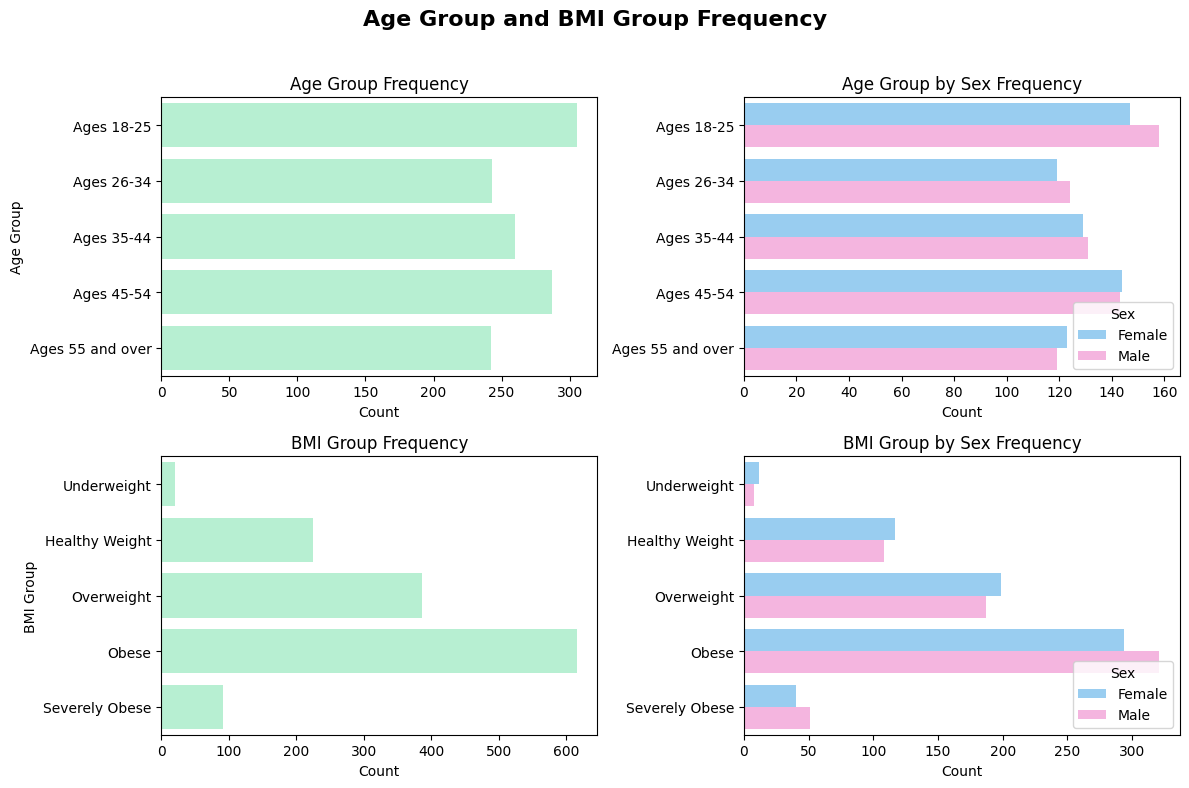

In [88]:
# Create subplots
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Define palettes for male and female
palette_sex = ["#8AD0FF", "#FFAAE3"]

# Top-left: Age group
sns.countplot(y='Age_Group', data=insurance, ax=axs[0, 0], color='#AEF8D2')
axs[0, 0].set_title('Age Group Frequency')
axs[0, 0].set_xlabel('Count')
axs[0, 0].set_ylabel('Age Group')

# Top-right: Age group by sex
sns.countplot(y='Age_Group', data=insurance, hue='Sex', ax=axs[0, 1], palette=palette_sex)
axs[0, 1].set_title('Age Group by Sex Frequency')
axs[0, 1].set_xlabel('Count')
axs[0, 1].set_ylabel('')
axs[0, 1].legend(title='Sex', loc='lower right')

# Bottom-left: BMI group
sns.countplot(y='BMI_Group', data=insurance, ax=axs[1, 0], color="#AEF8D2", 
              order=['Underweight', 'Healthy Weight', 'Overweight', 'Obese', 'Severely Obese'])
axs[1, 0].set_title('BMI Group Frequency')
axs[1, 0].set_xlabel('Count')
axs[1, 0].set_ylabel('BMI Group')

# Bottom-right: BMI group by sex
sns.countplot(y='BMI_Group', data=insurance, hue='Sex', ax=axs[1, 1], palette=palette_sex, 
              order=['Underweight', 'Healthy Weight', 'Overweight', 'Obese', 'Severely Obese'])
axs[1, 1].set_title('BMI Group by Sex Frequency')
axs[1, 1].set_xlabel('Count')
axs[1, 1].set_ylabel('')
axs[1, 1].legend(title='Sex', loc='lower right')

# Add overall title
fig.suptitle('Age Group and BMI Group Frequency', fontsize=16, fontweight='bold')

# Adjust spacing for suptitle
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**1.6.2 Create pie charts to look at the proportional distribution of plan, smoker, region and sex**

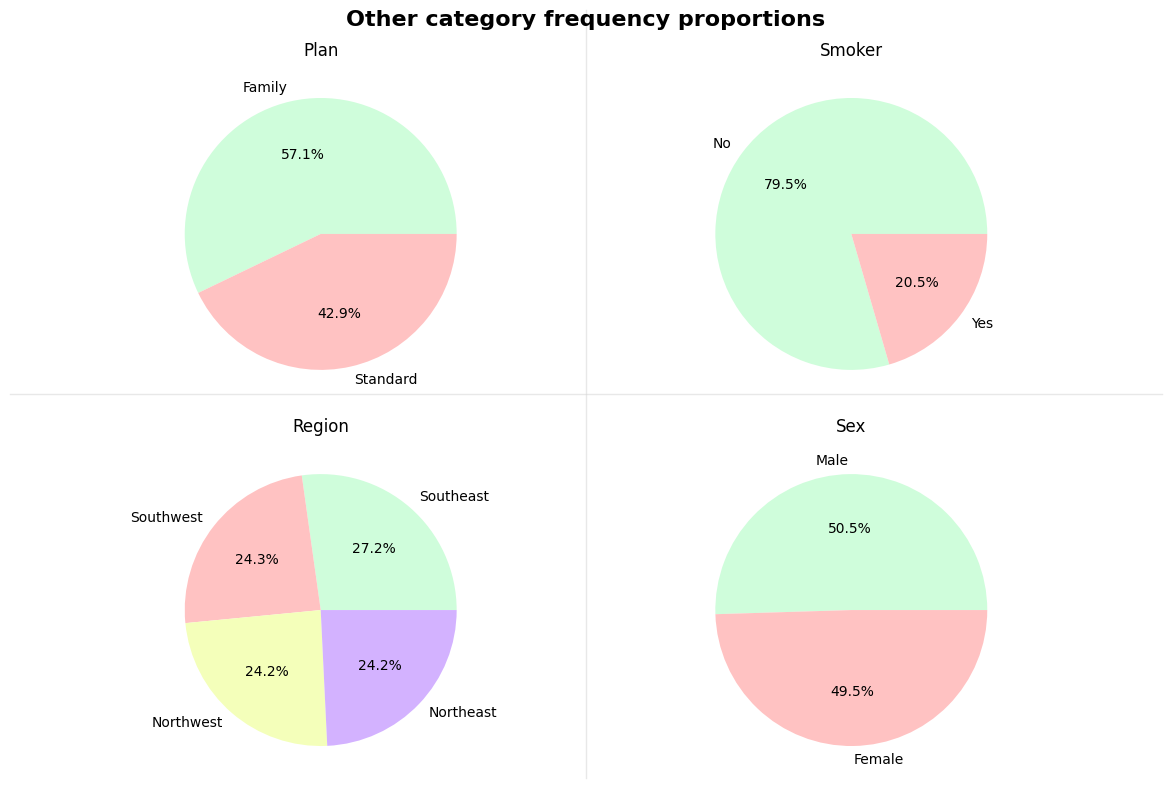

In [89]:
# Get value counts for each category
plan_counts = insurance['Plan'].value_counts(normalize=True)
smoker_counts = insurance['Smoker'].value_counts(normalize=True)
region_counts = insurance['Region'].value_counts(normalize=True)
sex_counts = insurance['Sex'].value_counts(normalize=True)

# Create subplots
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Top-left: Plan
axs[0, 0].pie(plan_counts.values, labels=plan_counts.index, autopct='%1.1f%%', 
              colors=["#CFFDDB","#FFC2C2"])
axs[0, 0].set_title('Plan')

# Top-right: Smoker
axs[0, 1].pie(smoker_counts.values, labels=smoker_counts.index, autopct='%1.1f%%', 
              colors=["#CFFDDB","#FFC2C2"])
axs[0, 1].set_title('Smoker')

# Bottom-left: Region
axs[1, 0].pie(region_counts.values, labels=region_counts.index, autopct='%1.1f%%', 
              colors=["#CFFDDB","#FFC2C2","#F4FFBA","#D3B2FF"])
axs[1, 0].set_title('Region')

# Bottom-right: Sex
axs[1, 1].pie(sex_counts.values, labels=sex_counts.index, autopct='%1.1f%%', 
              colors=["#CFFDDB","#FFC2C2"])
axs[1, 1].set_title('Sex')

# Add overall title
fig.suptitle('Other category frequency proportions', fontsize=16, fontweight='bold')

# Adjust spacing for suptitle
plt.tight_layout( pad=1.0)

# Add grid lines to separate the pie charts
fig.add_artist(mlines.Line2D([0.02, 0.98], [0.5, 0.5], color='lightgrey', 
                             linewidth=1, alpha=0.5, transform=fig.transFigure))
fig.add_artist(mlines.Line2D([0.5, 0.5], [0.02, 0.98], color='lightgrey', 
                             linewidth=1, alpha=0.5, transform=fig.transFigure))
plt.show()

**1.6.3 Charges Distribution**

**Create a histogram showing the distribution of charges and look at how much being a smoker affects the charge**

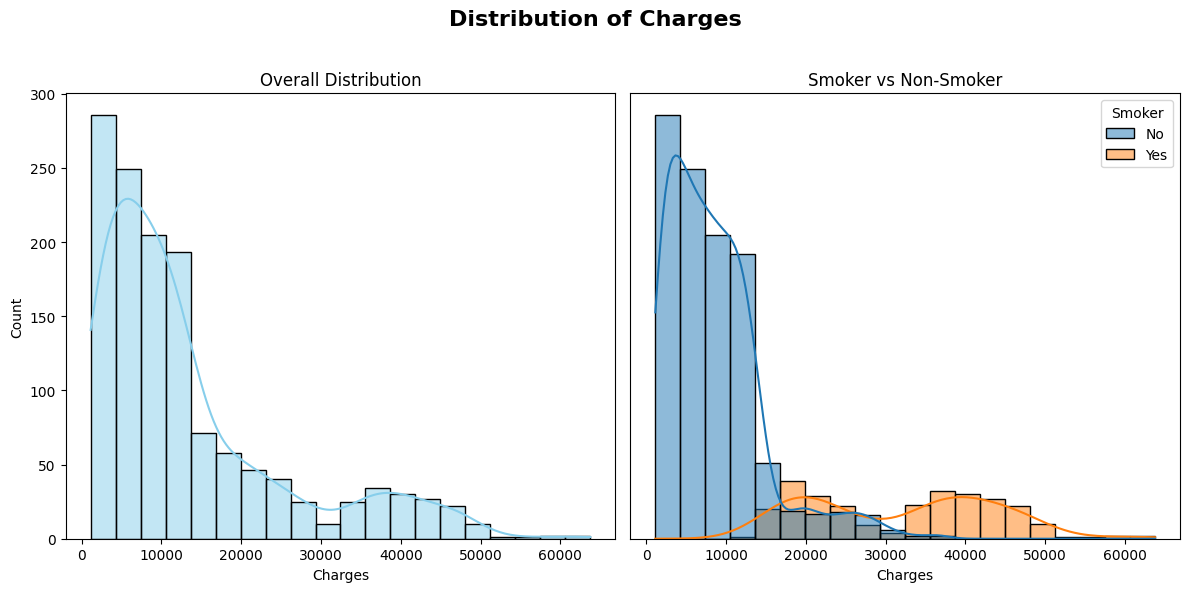

In [90]:
# Create subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# left: Overall
sns.histplot(data=insurance, x="Charges", kde=True, 
             bins=20, color="skyblue", ax=axs[0])
axs[0].set_title('Overall Distribution')

# right: Split by Smoker
sns.histplot(data=insurance, x="Charges", hue="Smoker", 
             kde=True, bins=20, color="skyblue", ax=axs[1])
axs[1].set_title('Smoker vs Non-Smoker')
axs[1].yaxis.set_visible(False)
axs[1].set_ylabel('')

# Add overall title
fig.suptitle('Distribution of Charges', fontsize=16, fontweight='bold')

# Adjust spacing for suptitle
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**1.6.4 Look at correlations**

**Display the numerical correlation figures between all numerical fields**

In [91]:
corr = insurance.corr(numeric_only=True)
corr

,Age,Age_Group_num,Sex_num,BMI,BMI_Group_num,Children,Plan_num,Smoker_num,Region_num,Charges,Charges_Per_Person,Charges_Outlier,Charges_Per_Person_Outlier
Age,1.000000,0.981051,-0.019814,0.109344,0.016935,0.041536,-0.045892,-0.025587,0.001626,0.298308,0.254871,0.045056,0.028595
Age_Group_num,0.981051,1.000000,-0.018485,0.103927,0.026107,0.043504,-0.049716,-0.032773,-0.001274,0.282417,0.241998,0.040470,0.021947
Sex_num,-0.019814,-0.018485,1.000000,0.046397,0.002622,0.017848,-0.015978,0.076596,0.004936,0.058044,0.033834,0.092264,0.016219
BMI,0.109344,0.103927,0.046397,1.000000,0.293990,0.012755,-0.016079,0.003746,0.157574,0.198401,0.147973,0.273764,0.097406
BMI_Group_num,0.016935,0.026107,0.002622,0.293990,1.000000,-0.015941,0.007367,-0.003350,0.024655,0.009383,0.000518,0.008647,-0.013177
Children,0.041536,0.043504,0.017848,0.012755,-0.015941,1.000000,-0.787420,0.007331,0.016258,0.067389,-0.358699,0.025810,-0.227240
Plan_num,-0.045892,-0.049716,-0.015978,-0.016079,0.007367,-0.787420,1.000000,-0.009093,-0.013289,-0.063985,0.378784,-0.037493,0.282560
Smoker_num,-0.025587,-0.032773,0.076596,0.003746,-0.003350,0.007331,-0.009093,1.000000,-0.002358,0.787234,0.644039,0.652707,0.464861
Region_num,0.001626,-0.001274,0.004936,0.157574,0.024655,0.016258,-0.013289,-0.002358,1.000000,-0.006547,0.001045,0.056040,0.018852
Charges,0.298308,0.282417,0.058044,0.198401,0.009383,0.067389,-0.063985,0.787234,-0.006547,1.000000,0.793999,0.811057,0.524285


**1.6.5 Create a scatter chart to show how much affect BMI and age have on both smokers and non-smokers:**

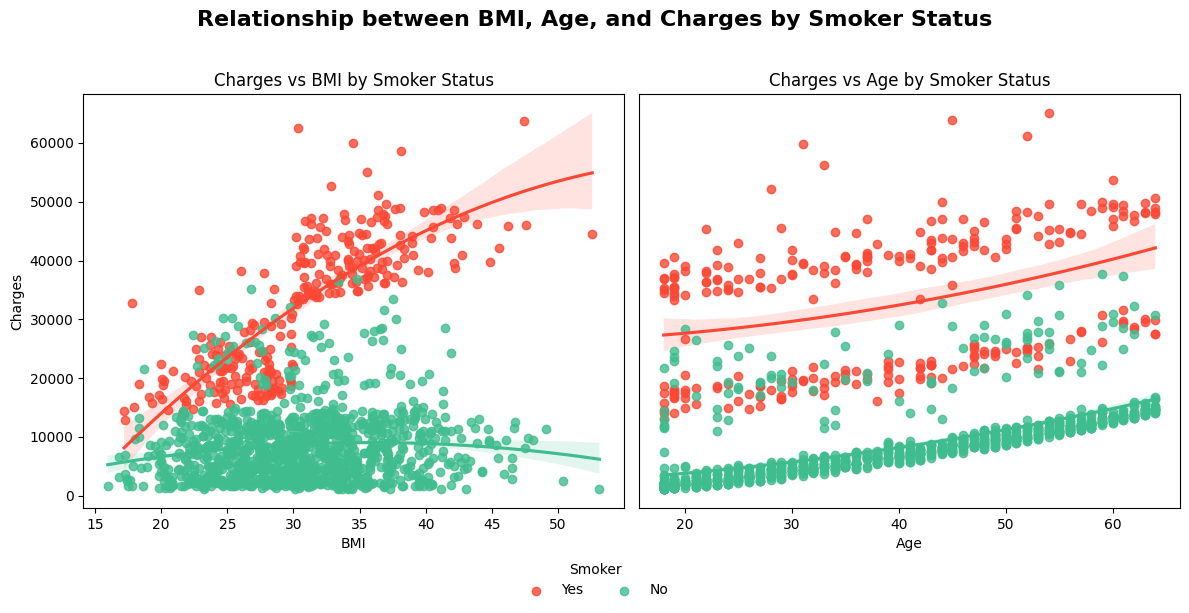

In [92]:
# Create subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# Plot for smokers BMI vs Charges
sns.regplot(
    data=insurance[insurance['Smoker'] == 'Yes'],
    x="BMI", y="Charges",
    order=2,
    scatter=True, 
    color="#FA4835",
    label="Yes",
    ax=axs[0]
)

# Plot for non-smokers BMI vs Charges
sns.regplot(
    data=insurance[insurance['Smoker'] == 'No'],
    x="BMI", y="Charges",
    order=2,
    scatter=True,
    color="#40BD8F", 
    label="No",
    ax=axs[0]
)

# Set title and hide y-axis label for BMI plot
axs[0].set_title("Charges vs BMI by Smoker Status")
axs[0].legend()

# Plot for smokers Age vs Charges
sns.regplot(
    data=insurance[insurance['Smoker'] == 'Yes'],
    x="Age", y="Charges",
    order=2,
    scatter=True, 
    color="#FA4835",
    label="Yes",
    ax=axs[1]
)

# Plot for non-smokers Age vs Charges
sns.regplot(
    data=insurance[insurance['Smoker'] == 'No'],
    x="Age", y="Charges",
    order=2,
    scatter=True,
    color="#40BD8F", 
    label="No",
    ax=axs[1]
)

# Set title, hide legend and hide y-axis for Age plot
axs[1].set_title("Charges vs Age by Smoker Status")
axs[1].legend()
axs[1].yaxis.set_visible(False)
axs[1].set_ylabel('')

# Remove individual legends
for ax in axs:
    ax.legend_.remove()

# Shared legend (note axs[0], not ax[0])
handles, labels = axs[0].get_legend_handles_labels()

# Add shared legend centered below plots
fig.legend(
    handles, labels,
    title='Smoker',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False
)

# Add overall title
fig.suptitle('Relationship between BMI, Age, and Charges by Smoker Status', 
             fontsize=16, fontweight='bold')

# Adjust spacing for suptitle
plt.tight_layout(rect=[0, 0, 1, 0.96])

# make space for the legend
plt.subplots_adjust(bottom=0.15)
plt.show()

**1.6.6 Create a scatter chart for each of the regions to show how the charges are distributed**

In [97]:
fig = px.scatter(
    insurance, x="BMI", y="Charges", 
    color="Smoker", facet_col="Region",
    height=700, opacity=0.85,
    color_discrete_map={"Yes": "#FA4835", "No": "#40BD8F"},
    title='Scatter of BMI vs Charges by Region and Smoker Status'
)

# Save figure as an image and show
# fig.write_image('../charts/scatter_bmi_charges_by_region.png')
fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

**1.6.7 Create a box plot for sex to show the distribution of charge data**

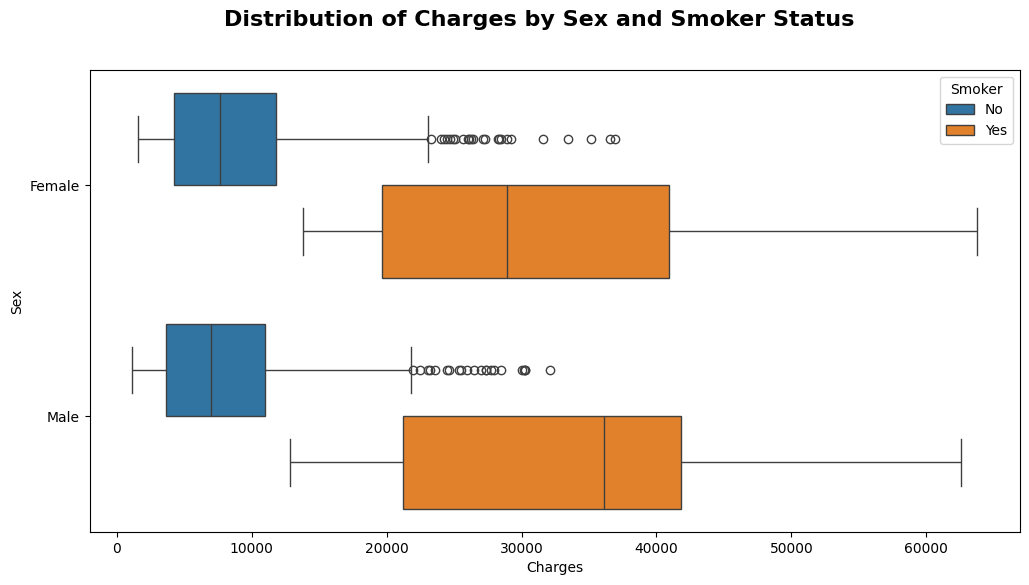

In [94]:
fig, axs = plt.subplots(1, 1, figsize=(12, 6))

sns.boxplot(data=insurance, x="Charges", y="Sex", hue="Smoker", orient="h", ax=axs)

# Add overall title
fig.suptitle('Distribution of Charges by Sex and Smoker Status', fontsize=16, fontweight='bold')
plt.show()

**1.6.8 Create a bar chart for the number of children and average charges**

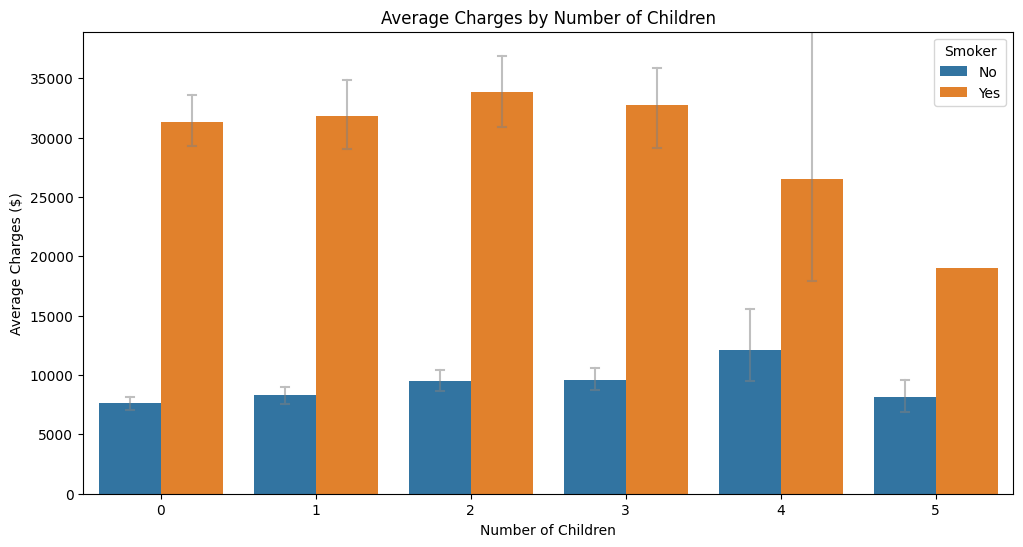

In [95]:
plt.figure(figsize=(12,6))

ax = sns.barplot(data=insurance, 
                 x="Children", y="Charges", 
                 hue="Smoker",
                 errorbar=("ci", 95),
                 err_kws={'color': (0.5, 0.5, 0.5, 0.5), 'linewidth': 1.5},
                 capsize=0.1)

# Increase y-axis limit to make room 
max_height = max([p.get_height() for p in ax.patches])
plt.ylim(0, max_height * 1.15) 

plt.title("Average Charges by Number of Children")
plt.ylabel("Average Charges ($)")
plt.xlabel("Number of Children")
plt.show()

---